# Phase 2: Data acquisition and setup
AI2002 Artificial Intelligence, Fall 2026 · Track B · Group 6

Ahmad Ali Khan (Lead, 24L-3049) · Talha Pasha (24L-3005) · Moeed Amir (24L-3060) · Bilal Kashif (24L-3036)

Run from the repository root. Everything below imports from `src/`.

In [1]:
import platform, sys
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common.io import ROOT, load_config
cfg = load_config('data')
print('python', platform.python_version(), '|', platform.platform())
print('pandas', pd.__version__, '| seed', cfg['seed'])

python 3.11.9 | Windows-10-10.0.26300-SP0
pandas 3.0.6 | seed 42


## 1. Data sources

In [2]:
sources = pd.DataFrame([
    ['mTREx', 'github.com/aisoc-lab/low-resource-hallucination-detection (data/mTREx)', 'commit 644d655', 'MIT'],
    ['X-FACTR', 'github.com/jzbjyb/x-factr (data/)', 'commit c1938ec', 'see data/README.md'],
    ['PsiloQA', 'huggingface.co/datasets/s-nlp/PsiloQA', 'load_dataset, 2026-10-18', 'see data/README.md'],
], columns=['dataset', 'source', 'version', 'licence'])
sources

,dataset,source,version,licence
0,mTREx,github.com/aisoc-lab/low-resource-hallucinatio...,commit 644d655,MIT
1,X-FACTR,github.com/jzbjyb/x-factr (data/),commit c1938ec,see data/README.md
2,PsiloQA,huggingface.co/datasets/s-nlp/PsiloQA,"load_dataset, 2026-10-18",see data/README.md


## 2. Collection
`scripts/download_data.sh` fetches the raw data (it skips anything already on disk).

In [3]:
import subprocess
out = subprocess.run(['bash', 'scripts/download_data.sh'], capture_output=True, text=True, cwd=ROOT,
                     env={**__import__('os').environ, 'PYTHON': sys.executable})
print(out.stdout[-600:], out.stderr[-300:] if out.returncode else '')
assert out.returncode == 0
for p in sorted((ROOT / 'data' / 'raw').iterdir()):
    print(p.name, sum(f.stat().st_size for f in p.rglob('*') if f.is_file()) // 2**20, 'MB')

mtrex_repo 644d6551e16c090a1ae3290c1d0e9635fcc157c7
xfactr c1938ec7262ebc34ac0b39daff3f446e103e8a87
 
mtrex_repo 4 MB
psiloqa 113 MB
xfactr 319 MB


## 3. Preprocessing
Each builder prints the row count before and after every step. The results are written to `data/processed/` in the shared schema (`src/common/schema.py`).

### 3.1 mTREx

In [4]:
from src.common.schema import write_jsonl
from src.datasets import mtrex, psiloqa, xfactr
records = {'mtrex': mtrex.build(cfg)}

mtrex English/capitals: raw 10000, non-empty 10000, unique source 10000
mtrex English/country: raw 10000, non-empty 10000, unique source 10000
mtrex English/official_language: raw 2375, non-empty 2375, unique source 2375
mtrex Deutsch/capitals: raw 10000, non-empty 10000, unique source 9624
mtrex Deutsch/country: raw 10000, non-empty 10000, unique source 9988
mtrex Deutsch/official_language: raw 2375, non-empty 2375, unique source 2140


mtrex Hindi/capitals: raw 2500, non-empty 2500, unique source 2485
mtrex Hindi/country: raw 2500, non-empty 2500, unique source 2499
mtrex Hindi/official_language: raw 2374, non-empty 2374, unique source 2156
mtrex Bengali/capitals: raw 2500, non-empty 2500, unique source 2484
mtrex Bengali/country: raw 2500, non-empty 2500, unique source 2500
mtrex Bengali/official_language: raw 2375, non-empty 2375, unique source 2195
mtrex Urdu/capitals: raw 2500, non-empty 2500, unique source 2479
mtrex Urdu/country: raw 2500, non-empty 2500, unique source 2499
mtrex Urdu/official_language: raw 2375, non-empty 2375, unique source 2154
mtrex: rows per language and category = 2140 (smallest cell)


mtrex: 32100 records


### 3.2 X-FACTR

In [5]:
records['xfactr'] = xfactr.build(cfg)

xfactr: 46 relations, dropped 0 gender-dependent or untemplated, kept 46


xfactr: 46000 facts in kept relations
xfactr ja: 25551 eligible facts
xfactr zh: 23278 eligible facts
xfactr vi: 13682 eligible facts
xfactr tl: 7213 eligible facts


xfactr sw: 6898 eligible facts
xfactr yo: 4643 eligible facts
xfactr ilo: 4060 eligible facts
xfactr ja: 1380 facts over 46 relations
xfactr zh: 1380 facts over 46 relations
xfactr vi: 1380 facts over 46 relations


xfactr tl: 1215 facts over 46 relations
xfactr sw: 1136 facts over 46 relations
xfactr yo: 856 facts over 42 relations
xfactr ilo: 834 facts over 42 relations
xfactr: 1796 distinct English facts, 9977 records


### 3.3 PsiloQA

In [6]:
records['psiloqa'] = psiloqa.build(cfg)
for name, recs in records.items():
    write_jsonl(ROOT / 'data' / 'processed' / f'{name}.jsonl', recs)

psiloqa: 39869 rows in chosen languages (train+validation+test pooled)
psiloqa: 39869 after dropping empty answers
psiloqa: 39856 after dropping duplicate question-answer pairs
psiloqa en: 1000 items, hallucination rate 0.96, models {'TinyLlama/TinyLlama-1.1B-Chat-v1.0': 119, 'ServiceNow-AI/Apriel-5B-Instruct': 195, 'HuggingFaceTB/SmolLM2-135M-Instruct': 32, 'HuggingFaceTB/SmolLM2-1.7B-Instruct': 33, 'HuggingFaceTB/SmolLM2-360M-Instruct': 32, 'HuggingFaceH4/zephyr-7b-beta': 37, 'togethercomputer/Pythia-Chat-Base-7B-v0.16': 113, 'tiiuae/falcon-7b-instruct': 88, 'microsoft/Phi-4-mini-instruct': 121, 'NousResearch/Nous-Hermes-2-Mistral-7B-DPO': 113, 'utter-project/EuroLLM-9B-Instruct': 117}


psiloqa hi: 1000 items, hallucination rate 0.87, models {'nickmalhotra/ProjectIndus': 263, 'google/gemma-7b-it': 252, 'sarvamai/sarvam-1': 485}
psiloqa zh: 1000 items, hallucination rate 0.87, models {'Qwen/Qwen2.5-3B-Instruct': 203, 'Qwen/Qwen2-7B-Instruct': 222, 'ikala/bloom-zh-3b-chat': 575}
psiloqa fi: 1000 items, hallucination rate 0.84, models {'Finnish-NLP/llama-7b-finnish-instruct-v0.2': 362, 'BSC-LT/salamandra-7b': 638}
psiloqa ar: 1000 items, hallucination rate 0.88, models {'SeaLLMs/SeaLLM-7B-v2.5': 1000}


In [7]:
# one example record per dataset
for name, recs in records.items():
    r = recs[len(recs) // 2]
    print(name, '|', r.language, '|', r.prompt[:90].replace('\n', ' '), '|', (r.gold or [r.answer[:40]])[:3])

mtrex | hi | प्रश्न: देउआ नदी किस देश में स्थित है? | ['ऑस्ट्रेलिया']
xfactr | tl | Tumutugtog si Ludwig van Beethoven ng ___ . | ['musikang klasiko']
psiloqa | zh | 疊石塘山超高樓項目的爭議之處有哪些方面？ | ['疊石塘山超高樓項目爭議主要集中在以下幾個方面：\n\n1. **環境保護**：項目建']


## 4. Exploratory analysis
`scripts/make_report_assets.py` rebuilds the tables and figures in `data/eda/`.

In [8]:
import runpy
runpy.run_path(str(ROOT / 'scripts' / 'make_report_assets.py'), run_name='not_main')['main']()

# EDA findings (generated by scripts/make_report_assets.py)

- mTREx: raw files range from 2374 rows (hi/official_language) to 10000; the smallest cell after cleaning fixes the sample at 2140 rows per language and category.
- mTREx: share of questions with more than one accepted answer by language: bn 29%, de 29%, en 30%, hi 29%, ur 29%.
- X-FACTR: every relation starts with 1000 facts, but after label filtering ilo keeps 1 to 980 per relation (median 22) and 4 relations disappear, hence the cap of 30.
- X-FACTR: entity labels fall from 33954 (ja) to 2241 (ilo); accepted answers per fact: ja 3.04, zh 3.09, vi 2.22, tl 2.47, sw 1.28, yo 1.5, ilo 1.35.
- X-FACTR: 1796 distinct English facts back 8181 non-English records, so the English side is small and shared.
- PsiloQA: hallucination rate per language: ar 0.88, en 0.96, fi 0.84, hi 0.87, zh 0.87; correct answers out of 1,000: ar 118, en 43, fi 160, hi 132, zh 130.
- PsiloQA: spans are long: the median hallucinated answer is 40% covered

### mTREx

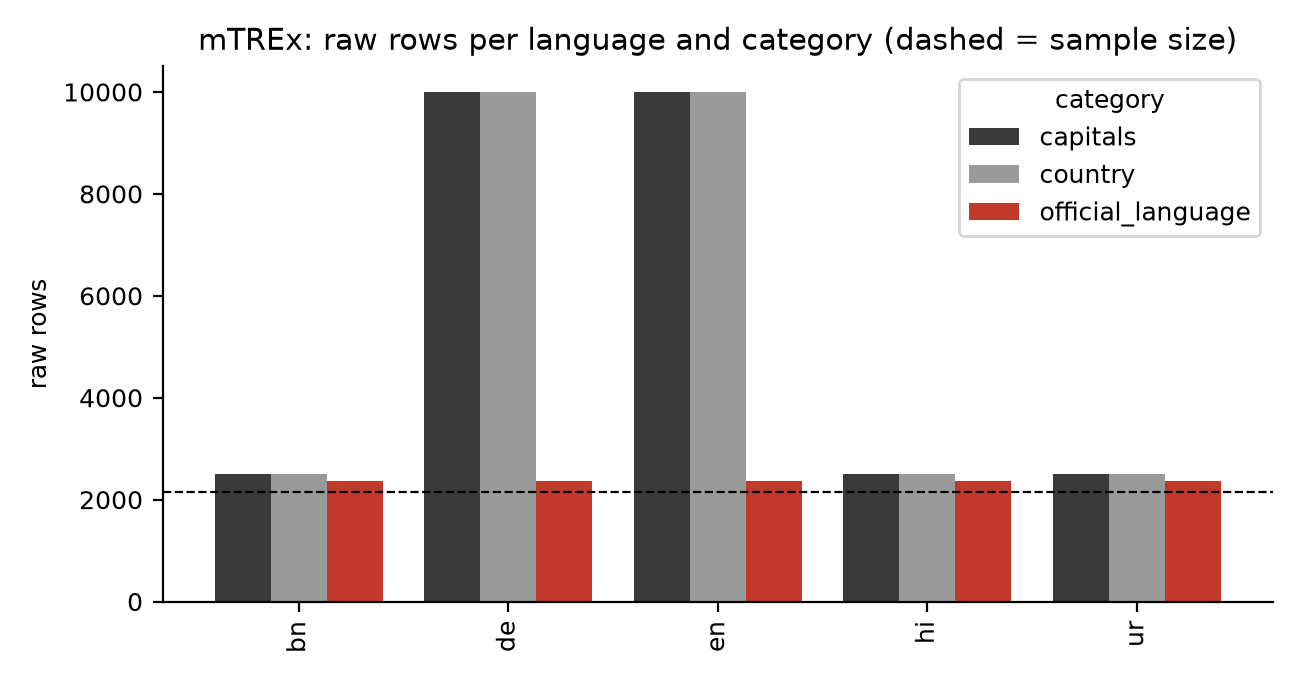

,language,mean_accepted_answers,multi_answer_share,mean_question_chars
0,bn,1.57,0.29,40.88
1,de,1.60,0.29,50.47
2,en,1.62,0.30,56.89
3,hi,1.56,0.29,45.44
4,ur,1.57,0.29,40.94


In [9]:
display(Image(ROOT / 'data/eda/mtrex_rows.png', width=640))
pd.read_csv(ROOT / 'data/eda/mtrex_answers.csv')

### X-FACTR

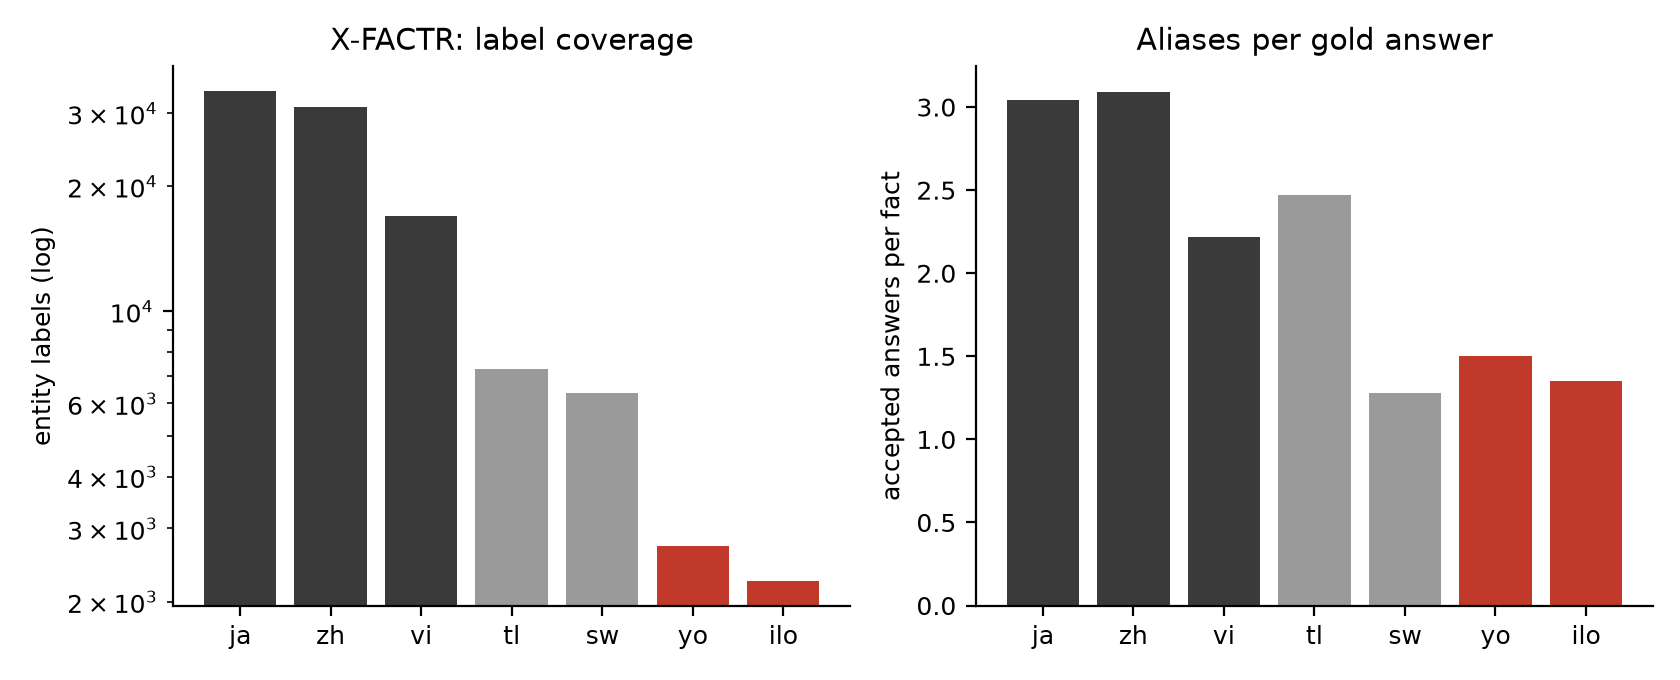

,language,group,script,label_count,eligible_facts,sampled_facts,mean_accepted_answers,median_gold_chars,relations
0,ja,high,Japanese,33954,25551,1380,3.04,5.0,46
1,zh,high,Han,30985,23278,1380,3.09,3.0,46
2,vi,high,Latin,16960,13682,1380,2.22,9.0,46
3,tl,medium,Latin,7275,7213,1215,2.47,8.0,46
4,sw,medium,Latin,6362,6898,1136,1.28,8.0,46
5,yo,low,Latin,2715,4643,856,1.50,9.0,42
6,ilo,low,Latin,2241,4060,834,1.35,7.0,42


In [10]:
display(Image(ROOT / 'data/eda/xfactr_coverage.png', width=640))
pd.read_csv(ROOT / 'data/eda/xfactr_languages.csv')

### PsiloQA

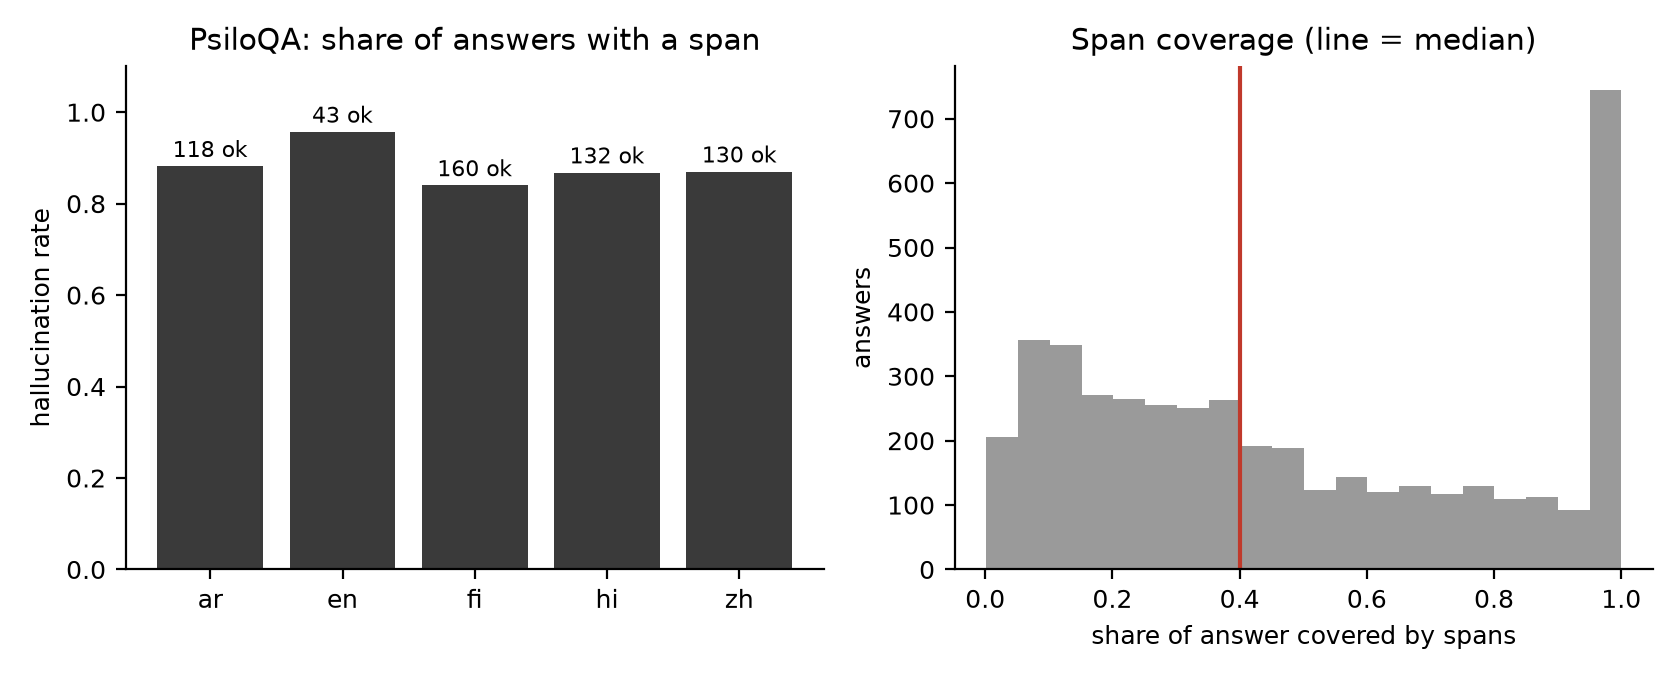

,language,items,hallucination_rate,mean_answer_chars,mean_answer_words,mean_spans,mean_span_share,correct_answers
0,ar,1000,0.882,165.896,27.970,1.332,0.374,118
1,en,1000,0.957,343.182,54.933,1.821,0.456,43
2,fi,1000,0.840,95.371,11.016,0.921,0.565,160
3,hi,1000,0.868,270.704,50.668,1.135,0.401,132
4,zh,1000,0.870,116.207,3.888,1.213,0.323,130


In [11]:
display(Image(ROOT / 'data/eda/psiloqa_spans.png', width=640))
pd.read_csv(ROOT / 'data/eda/psiloqa_languages.csv')

## 5. Final dataset summary
Built from the processed files, never typed by hand.

In [12]:
from src.common.schema import read_jsonl
rows = []
for name in ('mtrex', 'xfactr', 'psiloqa'):
    recs = read_jsonl(ROOT / 'data' / 'processed' / f'{name}.jsonl')
    rows.append({'dataset': name, 'rows': len(recs), 'languages': ', '.join(sorted({r.language for r in recs})),
                 'label': 'from spans' if name == 'psiloqa' else 'Phase 3 (gold match)',
                 'fields': 'uid, dataset, language, relation, prompt, gold, answer, spans, label, pair_uid, meta'})
pd.DataFrame(rows)

,dataset,rows,languages,label,fields
0,mtrex,32100,"bn, de, en, hi, ur",Phase 3 (gold match),"uid, dataset, language, relation, prompt, gold..."
1,xfactr,9977,"en, ilo, ja, sw, tl, vi, yo, zh",Phase 3 (gold match),"uid, dataset, language, relation, prompt, gold..."
2,psiloqa,5000,"ar, en, fi, hi, zh",from spans,"uid, dataset, language, relation, prompt, gold..."
